# Run previous notebook

In [1]:
# %run 01_eda_freight.ipynb

In [2]:
# from IPython.utils.capture import capture_output

# with capture_output():
#     get_ipython().run_line_magic('run', '01_eda_freight.ipynb')

In [3]:
# %pip install phik

In [4]:
# Imports
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
# import phik
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error
# Paths
DATA_DIR = Path("..") / "data"
CHARTS_DIR = Path("..") / "charts"
CHARTS_DIR.mkdir(parents=True, exist_ok=True)

In [5]:
# Rhine Freight Data
df_freight = pd.read_csv(DATA_DIR / "RhineFreightData.csv", sep=";")
df_freight['Date'] = pd.to_datetime(df_freight['Date'], dayfirst=True) 
# Drop empty rows
df_freight = df_freight.dropna(how="all")

# Weather Data
df_weather = pd.read_csv(DATA_DIR / "WeatherDataBasel.csv", sep=";")
df_weather['date'] = pd.to_datetime(df_weather['date'], dayfirst=True) # dates are dd/mm/yyyy
# Drop empty rows
df_weather = df_weather.dropna(how="all")
df_weather.rename(columns={'date': 'Date'}, inplace=True)

In [6]:
df_complete = pd.merge(df_freight, df_weather, on='Date', how='left')

In [7]:
df_freight.shape, df_weather.shape, df_complete.shape

((1469, 8), (3652, 25), (1469, 32))

In [8]:
df_complete.head()

,Date,Freight,Mogas_Flat,Brent_flat,Diesel_Flat,Heating_Flat,Kaub_level,freight_ar,avg_uv_index,avgtemp,...,totalsnow,uv_index,visibility,weather_code,weather_descriptions,wind_degree,wind_dir,wind_speed,windchill,windgust
0,2013-01-03,44.55,573.622200,260.662494,572.019772,554.576878,430.0,NaN,1.0,2.0,...,0.0,1.0,10.0,122.0,['Overcast'],245.0,WSW,7.0,1.0,14.0
1,2013-01-04,41.55,577.435102,260.252075,574.219032,557.993052,389.0,NaN,1.0,4.0,...,0.0,1.0,0.0,248.0,['Fog'],283.0,WNW,6.0,3.0,12.0
2,2013-01-07,41.55,576.174887,258.999923,578.355303,561.713421,327.0,NaN,1.0,1.0,...,0.0,1.0,10.0,113.0,['Clear'],105.0,ESE,5.0,-2.0,10.0
3,2013-01-08,40.05,577.156585,259.078404,579.239037,562.503444,329.0,NaN,1.0,0.0,...,0.0,1.0,10.0,113.0,['Clear'],210.0,SSW,4.0,0.0,8.0
4,2013-01-09,38.55,578.066208,259.375000,583.323044,567.144726,320.0,NaN,1.0,-1.0,...,0.0,1.0,5.0,143.0,['Mist'],273.0,W,5.0,-3.0,10.0


In [9]:
df_complete.shape

(1469, 32)

In [10]:
df_complete.drop(columns=['avg_uv_index', 'uv_index', "weather_code", "wind_dir"], inplace=True)

In [11]:
df_complete.dropna(subset=['Freight'], inplace=True)
# Price 5 rows ahead (the last 5 rows get NaN because they have no future)
df_complete['Freight_5days'] = df_complete['Freight'].shift(-5)
# Drop those last 5 rows
df_complete = df_complete.dropna(subset=['Freight_5days']).reset_index(drop=True)


# 2. Features

- Que features são mais importantes para o modelo?
- Que features são redundantes?
- Que tipo de split fazer? Cross-validation? Ter a certeza que nao existe data leakage
- Que modelos usar?
- Experimentar PCA para reduzir Weather features e gas price features?

Eliminar features claramente redundantes

In [12]:
df_complete.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  1449 non-null   datetime64[ns]
 1   Freight               1449 non-null   float64       
 2   Mogas_Flat            1449 non-null   float64       
 3   Brent_flat            1449 non-null   float64       
 4   Diesel_Flat           1449 non-null   float64       
 5   Heating_Flat          1449 non-null   float64       
 6   Kaub_level            1436 non-null   float64       
 7   freight_ar            714 non-null    float64       
 8   avgtemp               1449 non-null   float64       
 9   cloudcover            1449 non-null   float64       
 10  dewpoint              1449 non-null   float64       
 11  feelslike             1449 non-null   float64       
 12  heatindex             1449 non-null   float64       
 13  humidity          

In [13]:
# corr_above30 = (
#     correlation_matrix['Freight_5days']
#     .loc[lambda s: s > 0.30]            # arbitrary value could be 0.4, 0.5 etc
#     .drop('Freight_5days', errors='ignore')   # remove the target's correlation with itself (1.0)
#     .sort_values(ascending=False)
#     .rename('Correlation')
#     .to_frame()
# )

# corr_above30.round(3)

Encoding features

In [14]:
df_complete.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 29 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   Date                  1449 non-null   datetime64[ns]
 1   Freight               1449 non-null   float64       
 2   Mogas_Flat            1449 non-null   float64       
 3   Brent_flat            1449 non-null   float64       
 4   Diesel_Flat           1449 non-null   float64       
 5   Heating_Flat          1449 non-null   float64       
 6   Kaub_level            1436 non-null   float64       
 7   freight_ar            714 non-null    float64       
 8   avgtemp               1449 non-null   float64       
 9   cloudcover            1449 non-null   float64       
 10  dewpoint              1449 non-null   float64       
 11  feelslike             1449 non-null   float64       
 12  heatindex             1449 non-null   float64       
 13  humidity          

Encoding Date into cos e sin

In [15]:
doy = df_complete['Date'].dt.dayofyear
df_complete['Date_sin'] = np.sin(2 * np.pi * doy / 365.25)
df_complete['Date_cos'] = np.cos(2 * np.pi * doy / 365.25)

In [16]:
df_complete[["Date_sin", "Date_cos"]].head()

,Date_sin,Date_cos
0,0.051584,0.998669
1,0.068755,0.997634
2,0.120126,0.992759
3,0.137185,0.990545
4,0.154204,0.988039


Encoding Weather Description

In [17]:
df_complete["weather_descriptions"] = df_complete["weather_descriptions"].str.strip("[]'")

In [18]:
df_complete = pd.get_dummies(df_complete, columns=['weather_descriptions'], prefix='weather', dtype=int)

In [19]:
df_complete = pd.get_dummies(df_complete, columns=['moon_phase'], prefix='moon', dtype=int)

In [20]:
df_complete.columns

Index(['Date', 'Freight', 'Mogas_Flat', 'Brent_flat', 'Diesel_Flat',
       'Heating_Flat', 'Kaub_level', 'freight_ar', 'avgtemp', 'cloudcover',
       'dewpoint', 'feelslike', 'heatindex', 'humidity', 'maxtemp', 'mintemp',
       'moon_illumination', 'precip', 'pressure', 'sunhour', 'totalsnow',
       'visibility', 'wind_degree', 'wind_speed', 'windchill', 'windgust',
       'Freight_5days', 'Date_sin', 'Date_cos', 'weather_Clear',
       'weather_Cloudy', 'weather_Fog', 'weather_Freezing fog',
       'weather_Light rain', 'weather_Light rain shower', 'weather_Mist',
       'weather_Moderate or heavy rain shower', 'weather_Moderate rain',
       'weather_Overcast', 'weather_Partly cloudy',
       'weather_Patchy light rain with thunder',
       'weather_Patchy rain possible', 'weather_Thundery outbreaks possible',
       'moon_First Quarter', 'moon_Full Moon', 'moon_Last Quarter',
       'moon_New Moon', 'moon_Waning Crescent', 'moon_Waning Gibbous',
       'moon_Waxing Crescent', 'm

In [21]:
df_complete.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1449 entries, 0 to 1448
Data columns (total 51 columns):
 #   Column                                  Non-Null Count  Dtype         
---  ------                                  --------------  -----         
 0   Date                                    1449 non-null   datetime64[ns]
 1   Freight                                 1449 non-null   float64       
 2   Mogas_Flat                              1449 non-null   float64       
 3   Brent_flat                              1449 non-null   float64       
 4   Diesel_Flat                             1449 non-null   float64       
 5   Heating_Flat                            1449 non-null   float64       
 6   Kaub_level                              1436 non-null   float64       
 7   freight_ar                              714 non-null    float64       
 8   avgtemp                                 1449 non-null   float64       
 9   cloudcover                              1449 non-nul

## Missing values

Strategies:
-   **freight_ar**
    -   drop column
    -   replace missing values with mean (not the best approach probably)
-   **Kaub level**
    - replace with the mean between the values right before and after

In [22]:
# Kaub_level: average of the value before and the value after each gap
df_complete["Kaub_level"] = df_complete["Kaub_level"].interpolate(method="linear", limit_area="inside")

# freight_ar: fill missing values with the column mean
df_complete["freight_ar"] = df_complete["freight_ar"].fillna(df_complete["freight_ar"].mean())
#drop freight_ar from the dataset
#df = df_complete.drop(columns=["freight_ar"])

# 1. Baseline Model

In [23]:
col = 'Freight'

# Garante a ordem temporal (se tiveres uma coluna Date)
df_sorted = df_complete.sort_values('Date').reset_index(drop=True)
y = df_sorted[col]

# 1) Maior amplitude em 5 linhas seguidas (como antes)
amplitude = y.rolling(5).max() - y.rolling(5).min()
print('Maior amplitude em 5 linhas:', amplitude.max())

# 2) Previsão = média dos 5 dias anteriores (shift(1) exclui o próprio dia)
pred_mean5 = y.shift(1).rolling(5).mean()
erro_mean5 = (y - pred_mean5).abs()

# 3) Previsão = valor do dia anterior
pred_naive = y.shift(1)
erro_naive = (y - pred_naive).abs()

# Resultados
for nome, erro, pred in [('Média dos 5 dias anteriores', erro_mean5, pred_mean5),
                         ('Valor do dia anterior', erro_naive, pred_naive)]:
    i = erro.idxmax()
    print(f'\n{nome}')
    print('  Erro máximo:', round(erro[i], 2))
    print('  Erro médio (MAE):', round(erro.mean(), 2))
    print('  Valor real:', y[i], '| Previsão:', round(pred[i], 2))
    print('  Linha:', i)

Maior amplitude em 5 linhas: 224.39999999999998

Média dos 5 dias anteriores
  Erro máximo: 177.39
  Erro médio (MAE): 3.89
  Valor real: 151.35 | Previsão: 328.74
  Linha: 1438

Valor do dia anterior
  Erro máximo: 112.35
  Erro médio (MAE): 1.41
  Valor real: 248.1 | Previsão: 360.45
  Linha: 1437


In [24]:
# Previsões (usam só informação até ao dia t)
df_complete['pred_hoje']     = df_complete['Freight']
df_complete['pred_media5']   = df_complete['Freight'].rolling(5).mean()
# Hoje + variação dos últimos 5 dias = 2*y(t) - y(t-5)
df_complete['pred_momentum'] = df_complete['Freight'] + df_complete['Freight'].diff(5)

previsores = {
    'Preço de hoje': 'pred_hoje',
    'Média dos últimos 5 dias': 'pred_media5',
    'Hoje + variação 5 dias': 'pred_momentum',
}

# Mesmas linhas para os três métodos (media5 e momentum geram NaN nas primeiras linhas)
av = df_complete.dropna(subset=list(previsores.values()) + ['Freight_5days'])

def metricas(y_true, y_pred):
    erro = y_true - y_pred
    return {
        'MAE': erro.abs().mean(),
        'RMSE': np.sqrt((erro ** 2).mean()),
        'Erro máx': erro.abs().max(),
    }

# Todos os dias
resultados = pd.DataFrame({
    nome: metricas(av['Freight_5days'], av[col])
    for nome, col in previsores.items()
}).T

print(f'Nº de previsões avaliadas: {len(av)}')
display(resultados.round(2))

# Só dias extremos (top 10% do preço real a 5 dias)
extremo = av['Freight_5days'] >= av['Freight_5days'].quantile(0.90)

resultados_ext = pd.DataFrame({
    nome: metricas(av.loc[extremo, 'Freight_5days'], av.loc[extremo, col])
    for nome, col in previsores.items()
}).T

print('Dias extremos:')
display(resultados_ext.round(2))

Nº de previsões avaliadas: 1444


,MAE,RMSE,Erro máx
Preço de hoje,6.39,15.97,227.7
Média dos últimos 5 dias,8.47,19.44,214.2
Hoje + variação 5 dias,7.46,19.24,247.8


Dias extremos:


,MAE,RMSE,Erro máx
Preço de hoje,22.79,41.97,227.7
Média dos últimos 5 dias,26.96,44.07,214.2
Hoje + variação 5 dias,22.59,42.79,247.8


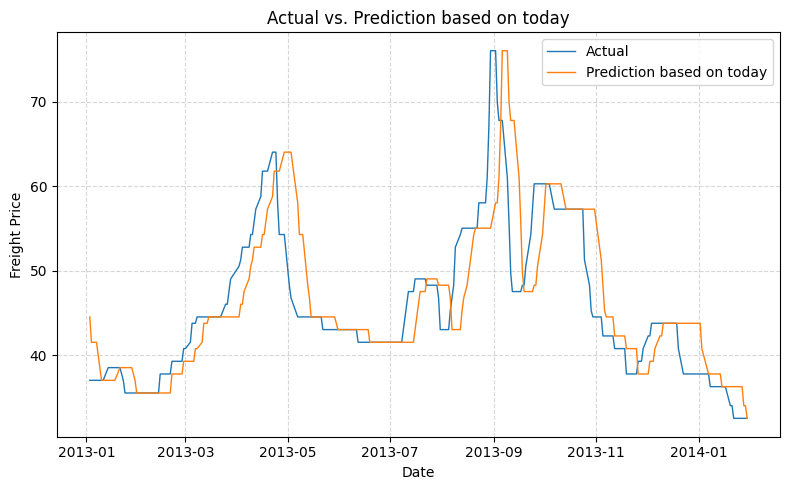

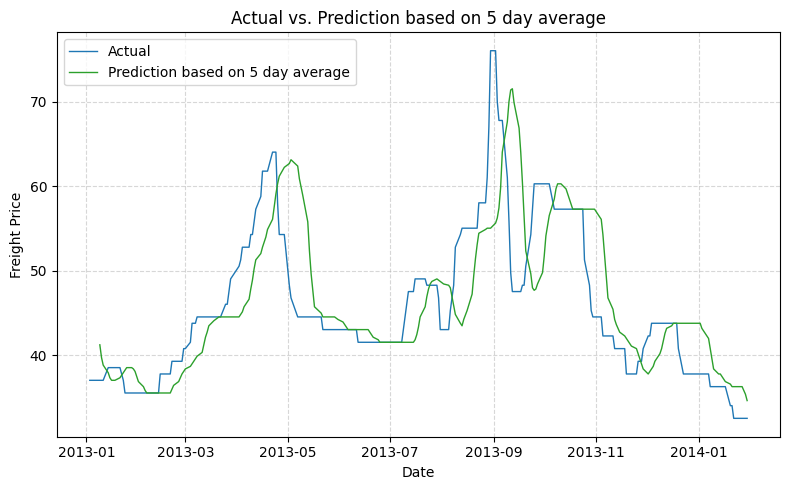

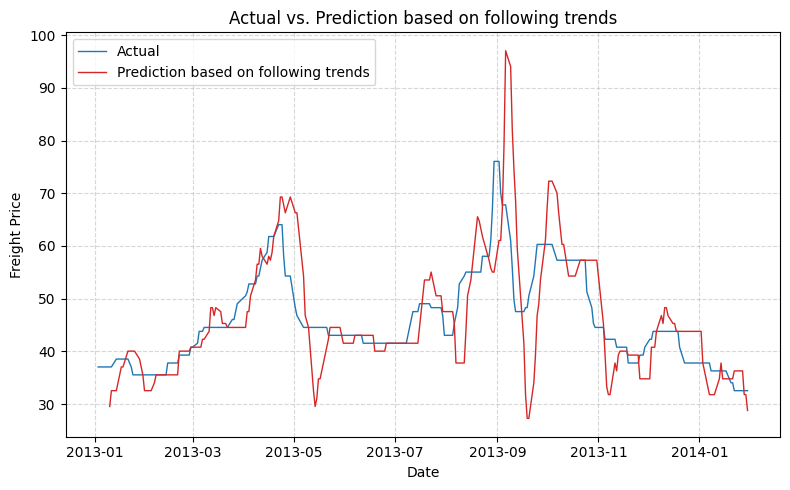

In [25]:
year = int(365 * 5 / 7)
subset = df_complete.iloc[:year]
x = subset['Date']

# Define (column_name, legend_label, line_color) for each baseline
baselines = [
    ('pred_hoje', 'Prediction based on today', '#ff7f0e'),
    ('pred_media5', 'Prediction based on 5 day average', '#2ca02c'),
    ('pred_momentum', 'Prediction based on following trends', '#d62728'),
]

for col, label, color in baselines:
    fig, ax = plt.subplots(figsize=(8, 5))
    
    ax.plot(x, subset['Freight_5days'], label='Actual', color='#1f77b4', linewidth=1)
    ax.plot(x, subset[col], label=label, color=color, linewidth=1)
    
    ax.set(title=f'Actual vs. {label}', xlabel='Date', ylabel='Freight Price')
    ax.grid(True, linestyle='--', alpha=0.5)
    ax.legend(loc='best')
    
    plt.tight_layout()

plt.show()

Cada hipotese de baseline tem vantagens e desvantagens. Pelos resultados a melhor baseline é assumir o preço de hoje para a previsao.
A media dos ultimos 5 dias tende  atrasar o sinal da trend na previsao piorando os resultados. 
A tentativa de seguir a tendencia (Hoje + variação) resulta em menores erros no inicio de tendencias mas erros amplificados quando o crescimento/diminuição de preço muda de sentido.

Por enquanto a baseline escolhida é o preço do proprio dia

## Train/Test split

TimeSeriesSplit
-   no max  max_train_size
-   max_train_size=500

In [26]:
df_model = df_complete.copy()  # Create a copy of df_complete to avoid modifying the original DataFrame

target = "Freight_5days"
baselines = ["pred_hoje", "pred_media5", "pred_momentum"]   # keep for comparison, not as features
drop_cols = ["Date", target] + baselines

X = df_model.drop(columns=drop_cols, errors="ignore")
y = df_model[target]
dates = df_model["Date"]

# gap=5: the last 5 training rows have targets that fall inside the test period -> leave them out
splitters = {
    "expanding (default)": TimeSeriesSplit(n_splits=5, gap=5),                        # train on all past data
    "rolling (500)":       TimeSeriesSplit(n_splits=5, gap=5, max_train_size=500),    # train on the last 500 rows only
}

folds = []
for scheme, tscv in splitters.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        folds.append({
            "scheme": scheme,
            "fold": fold,
            "train_start": dates.iloc[train_idx[0]].date(), "train_end": dates.iloc[train_idx[-1]].date(),
            "train_rows": len(train_idx),
            "test_start": dates.iloc[test_idx[0]].date(), "test_end": dates.iloc[test_idx[-1]].date(),
            "test_rows": len(test_idx),
        })
folds = pd.DataFrame(folds).set_index(["scheme", "fold"])
folds

train_start   train_end  train_rows  test_start  \
scheme              fold                                                   
expanding (default) 0     2013-01-03  2013-12-23         239  2014-01-08   
                    1     2013-01-03  2014-12-22         480  2015-01-07   
                    2     2013-01-03  2015-12-18         721  2016-01-04   
                    3     2013-01-03  2016-12-16         962  2016-12-28   
                    4     2013-01-03  2017-12-15        1203  2017-12-27   
rolling (500)       0     2013-01-03  2013-12-23         239  2014-01-08   
                    1     2013-01-03  2014-12-22         480  2015-01-07   
                    2     2013-11-28  2015-12-18         500  2016-01-04   
                    3     2014-11-27  2016-12-16         500  2016-12-28   
                    4     2015-11-25  2017-12-15         500  2017-12-27   

                            test_end  test_rows  
scheme              fold                         
expanding (default) 0     2015-01-05        241  
                    1     2015-12-30        241  
                    2     2016-12-23        241  
                    3     2017-12-22        241  
                    4     2018-12-18        241  
rolling (500)       0     2015-01-05        241  
                    1     2015-12-30        241  
                    2     2016-12-23        241  
                    3     2017-12-22        241  
                    4     2018-12-18        241

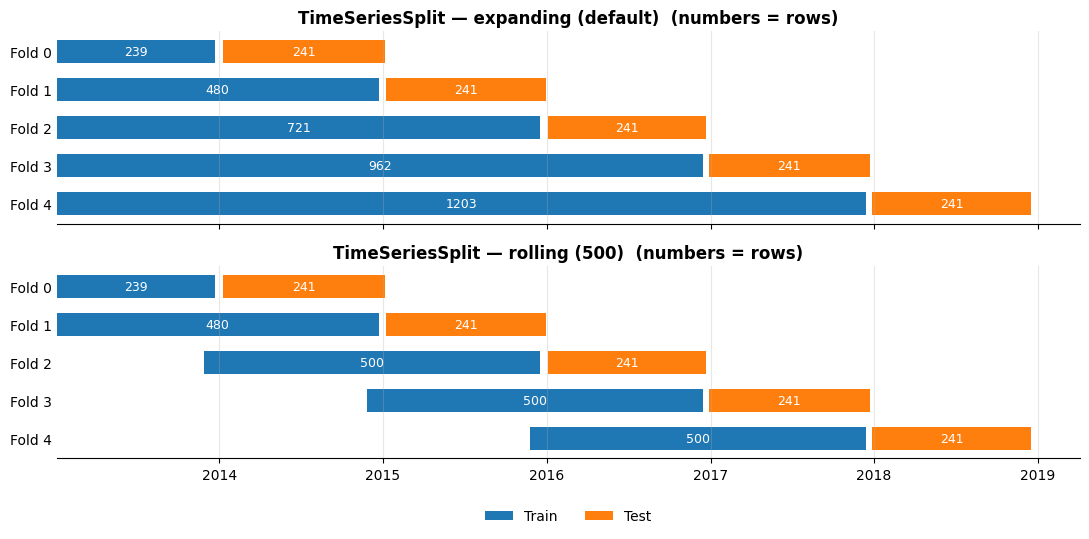

In [27]:
fig, axes = plt.subplots(len(splitters), 1, figsize=(11, 5.5), sharex=True)
for ax, (scheme, tscv) in zip(axes, splitters.items()):
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        tr0, tr1 = dates.iloc[train_idx[0]], dates.iloc[train_idx[-1]]
        te0, te1 = dates.iloc[test_idx[0]], dates.iloc[test_idx[-1]]
        ax.barh(fold, tr1 - tr0, left=tr0, height=0.6, color="tab:blue", label="Train" if fold == 0 else None)
        ax.barh(fold, te1 - te0, left=te0, height=0.6, color="tab:orange", label="Test" if fold == 0 else None)
        ax.text(tr0 + (tr1 - tr0) / 2, fold, f"{len(train_idx)}", va="center", ha="center", color="white", fontsize=9)
        ax.text(te0 + (te1 - te0) / 2, fold, f"{len(test_idx)}", va="center", ha="center", color="white", fontsize=9)
    ax.set_yticks(range(tscv.n_splits), [f"Fold {i}" for i in range(tscv.n_splits)])
    ax.invert_yaxis()
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", alpha=0.3)
    ax.set_title(f"TimeSeriesSplit — {scheme}  (numbers = rows)", loc="center", fontweight="bold")
axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[-1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2, frameon=False)
plt.tight_layout(); plt.show()

## Modeling

Strategies:
-   Using all features
-   keeping only energies, kaub level, 

### Linear Regression Ridge

In [28]:
models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    # "RandomForest": make_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)),
    # "HistGB": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=42),
}

results = []
for scheme, tscv in splitters.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # benchmark: freight in 5 days = freight today
        results.append({"scheme": scheme, "fold": fold, "model": "Benchmark (today)",
                        "MAE": mean_absolute_error(y_test, df_model["pred_hoje"].iloc[test_idx])})

        for name, model in models.items():
            model.fit(X_train, y_train)
            results.append({"scheme": scheme, "fold": fold, "model": name,
                            "MAE": mean_absolute_error(y_test, model.predict(X_test))})

res = pd.DataFrame(results)
res.pivot(index=["scheme", "fold"], columns="model", values="MAE").round(2)

model                     Benchmark (today)  Ridge
scheme              fold                          
expanding (default) 0                  2.27   9.21
                    1                  8.02  14.49
                    2                  5.43   9.62
                    3                  6.50   8.13
                    4                 12.65  16.25
rolling (500)       0                  2.27   9.21
                    1                  8.02  14.49
                    2                  5.43  11.51
                    3                  6.50  11.69
                    4                 12.65  23.77

In [ ]:
models = {
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    # "RandomForest": make_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=42)),
    # "HistGB": HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=300, random_state=42),
}

results = []
preds = []   # store every prediction for plotting
for scheme, tscv in splitters.items():
    for fold, (train_idx, test_idx) in enumerate(tscv.split(X)):
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

        # benchmark: freight in 5 days = freight today
        results.append({"scheme": scheme, "fold": fold, "model": "Benchmark (today)",
                        "MAE": mean_absolute_error(y_test, df_model["pred_hoje"].iloc[test_idx])})

        for name, model in models.items():
            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)
            results.append({"scheme": scheme, "fold": fold, "model": name,
                            "MAE": mean_absolute_error(y_test, y_pred)})
            preds.append(pd.DataFrame({"scheme": scheme, "fold": fold, "model": name, "Date": dates.iloc[test_idx].values,
                                       "actual": y_test.values, "pred": y_pred,
                                       "benchmark": df_model["pred_hoje"].iloc[test_idx].values}))

res = pd.DataFrame(results)
preds = pd.concat(preds, ignore_index=True)
res.pivot(index=["scheme", "fold"], columns="model", values="MAE").round(2)


                   scheme  fold  model       Date  actual        pred  \
0     expanding (default)     0  Ridge 2014-01-08   36.30   40.776457   
1     expanding (default)     0  Ridge 2014-01-09   36.30   40.317573   
2     expanding (default)     0  Ridge 2014-01-10   36.30   39.187579   
3     expanding (default)     0  Ridge 2014-01-13   36.30   36.418748   
4     expanding (default)     0  Ridge 2014-01-14   36.30   36.586098   
...                   ...   ...    ...        ...     ...         ...   
2405        rolling (500)     4  Ridge 2018-12-12  122.10  109.344737   
2406        rolling (500)     4  Ridge 2018-12-13  125.10  105.588910   
2407        rolling (500)     4  Ridge 2018-12-14  118.35  105.132282   
2408        rolling (500)     4  Ridge 2018-12-17  119.85  109.502594   
2409        rolling (500)     4  Ridge 2018-12-18  120.45  111.899520   

      benchmark  
0         37.80  
1         37.80  
2         37.80  
3         37.80  
4         37.80  
...         ...

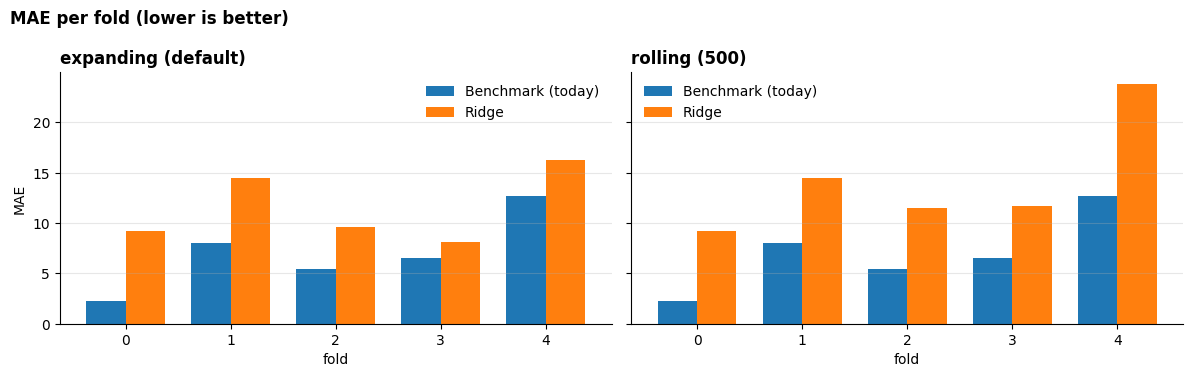

In [30]:
fig, axes = plt.subplots(1, len(splitters), figsize=(12, 3.8), sharey=True)
for ax, scheme in zip(axes, splitters):
    t = res[res["scheme"] == scheme].pivot(index="fold", columns="model", values="MAE")
    t.plot(kind="bar", ax=ax, width=0.75)
    ax.set_title(scheme, loc="left", fontweight="bold"); ax.set_xlabel("fold"); ax.set_ylabel("MAE")
    ax.tick_params(axis="x", rotation=0); ax.grid(axis="y", alpha=0.3); ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False)
fig.suptitle("MAE per fold (lower is better)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

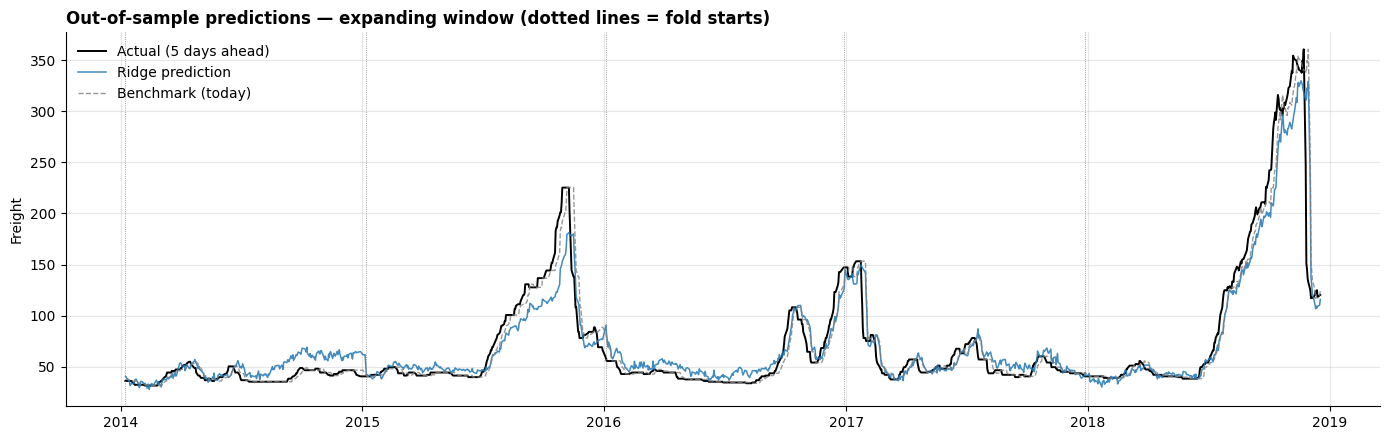

In [31]:
p = preds[(preds["scheme"] == "expanding (default)") & (preds["model"] == "Ridge")]
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(p["Date"], p["actual"], color="black", lw=1.4, label="Actual (5 days ahead)")
ax.plot(p["Date"], p["pred"], color="tab:blue", lw=1.1, alpha=0.85, label="Ridge prediction")
ax.plot(p["Date"], p["benchmark"], color="tab:grey", lw=1, ls="--", alpha=0.8, label="Benchmark (today)")
for f, g in p.groupby("fold"):
    ax.axvline(g["Date"].min(), color="grey", lw=0.6, ls=":")   # start of each test fold
ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylabel("Freight"); ax.legend(frameon=False, loc="upper left")
ax.set_title("Out-of-sample predictions — expanding window (dotted lines = fold starts)", loc="left", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

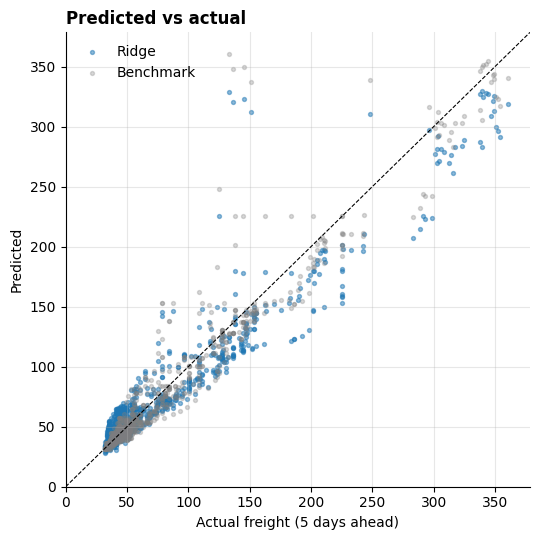

In [32]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(p["actual"], p["pred"], s=8, alpha=0.5, color="tab:blue", label="Ridge")
ax.scatter(p["actual"], p["benchmark"], s=8, alpha=0.3, color="tab:grey", label="Benchmark")
lim = [0, max(p["actual"].max(), p["pred"].max()) * 1.05]
ax.plot(lim, lim, color="black", lw=0.8, ls="--")   # perfect prediction line
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Actual freight (5 days ahead)"); ax.set_ylabel("Predicted")
ax.set_title("Predicted vs actual", loc="left", fontweight="bold")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()